# Predicting NBA Home-Team Wins from Pre-Game Information

**Goal:** predict whether the home team wins an NBA regular-season game using only information
available *before tip-off*.

**Data:** Eoin Moore, *Historical NBA Data and Player Box Scores* (Kaggle), files `Games.csv`
(one row per game) and `TeamStatistics.csv` (one row per team per game, with box-score totals).

**Plan:**
1. Load and inspect the raw files
2. Clean: regular season + NBA Cup only, seasons 2015-16 to 2025-26
3. Build leakage-free pre-game features
4. Time-based split, baseline, logistic regression and random forest
5. Bootstrap CIs, feature importance, calibration
6. Summary of final numbers

## 1. Load and inspect the raw data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA_DIR = "csv"
games_raw = pd.read_csv(f"{DATA_DIR}/Games.csv", low_memory=False)
tstats_raw = pd.read_csv(f"{DATA_DIR}/TeamStatistics.csv", low_memory=False)

print("Games.csv:", games_raw.shape)
print("TeamStatistics.csv:", tstats_raw.shape)

Games.csv: (73428, 23)
TeamStatistics.csv: (146858, 59)


In [2]:
games_raw.head()

,gameId,gameDateTimeEst,hometeamCity,hometeamName,hometeamId,awayteamCity,awayteamName,awayteamId,homeScore,awayScore,winner,gameType,gameSubtype,gameLabel,gameSubLabel,seriesGameNumber,attendance,arenaId,arenaName,arenaCity,arenaState,officials,gameDate
0,22600023,2026-10-30 22:00:00,Golden State,Warriors,1610612744,Los Angeles,Lakers,1610612747,112,95,1610612744,Regular Season,in-season,Emirates NBA Cup,West Group C,NaN,18064.0,1000011,Chase Center,San Francisco,CA,"Tony Brothers, John Butler, Jenna Schroeder",2026-10-30 22:00:00
1,22600024,2026-10-30 22:00:00,Phoenix,Suns,1610612756,Denver,Nuggets,1610612743,120,127,1610612743,Regular Season,in-season,Emirates NBA Cup,West Group A,NaN,17071.0,1000159,Mortgage Matchup Center,Phoenix,AZ,"Brian Forte, Tyler Ford, Mousa Dagher",2026-10-30 22:00:00
2,22600020,2026-10-30 20:00:00,Miami,Heat,1610612748,Indiana,Pacers,1610612754,145,125,1610612748,Regular Season,in-season,Emirates NBA Cup,East Group B,NaN,19653.0,1000100,Kaseya Center,Miami,FL,"Eric Lewis, Brent Barnaky, Brett Nansel",2026-10-30 20:00:00
3,22600021,2026-10-30 20:00:00,Dallas,Mavericks,1610612742,Houston,Rockets,1610612745,116,111,1610612742,Regular Season,in-season,Emirates NBA Cup,West Group A,NaN,18832.0,193,American Airlines Center,Dallas,TX,"Zach Zarba, Robert Hussey, Ashley Moyer-Gleich",2026-10-30 20:00:00
4,22600022,2026-10-30 20:00:00,Minnesota,Timberwolves,1610612750,LA,Clippers,1610612746,127,101,1610612750,Regular Season,in-season,Emirates NBA Cup,West Group B,NaN,17593.0,61,Target Center,Minneapolis,MN,"JB DeRosa, Marat Kogut, Che Flores",2026-10-30 20:00:00


In [3]:
print(list(games_raw.columns))
games_raw.info()

['gameId', 'gameDateTimeEst', 'hometeamCity', 'hometeamName', 'hometeamId', 'awayteamCity', 'awayteamName', 'awayteamId', 'homeScore', 'awayScore', 'winner', 'gameType', 'gameSubtype', 'gameLabel', 'gameSubLabel', 'seriesGameNumber', 'attendance', 'arenaId', 'arenaName', 'arenaCity', 'arenaState', 'officials', 'gameDate']
<class 'pandas.DataFrame'>
RangeIndex: 73428 entries, 0 to 73427
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gameId            73428 non-null  int64  
 1   gameDateTimeEst   73428 non-null  str    
 2   hometeamCity      73421 non-null  str    
 3   hometeamName      73428 non-null  str    
 4   hometeamId        73428 non-null  int64  
 5   awayteamCity      73421 non-null  str    
 6   awayteamName      73428 non-null  str    
 7   awayteamId        73428 non-null  int64  
 8   homeScore         73428 non-null  int64  
 9   awayScore         73428 non-null  int64  
 10  winner   

In [4]:
tstats_raw.head()

,regulagameId,gameDateTimeEst,teamCity,teamName,teamId,opponentTeamCity,opponentTeamName,opponentTeamId,home,win,teamScore,opponentScore,assists,blocks,steals,fieldGoalsAttempted,fieldGoalsMade,fieldGoalsPercentage,threePointersAttempted,threePointersMade,...,pointsFastBreak,pointsFromTurnovers,pointsInThePaint,pointsSecondChance,timesTied,timeoutsRemaining,seasonWins,seasonLosses,coachId,gameType,gameLabel,gameSubLabel,seriesGameNumber,seed,reboundsTeam,turnoversTeam,ot1Points,ot2Points,otAllPoints,gameDate
0,22600023,2026-10-30 22:00:00,Los Angeles,Lakers,1610612747,Golden State,Warriors,1610612744,0,0.0,95,112,18.0,11.0,8.0,82.0,33.0,0.402,39.0,11.0,...,9.0,25.0,36.0,17.0,2.0,1.0,4.0,2.0,NaN,Regular Season,Emirates NBA Cup,West Group C,NaN,NaN,11.0,2.0,NaN,NaN,NaN,2026-10-30 22:00:00
1,22600023,2026-10-30 22:00:00,Golden State,Warriors,1610612744,Los Angeles,Lakers,1610612747,1,1.0,112,95,31.0,5.0,11.0,89.0,38.0,0.427,46.0,22.0,...,18.0,27.0,28.0,21.0,2.0,1.0,3.0,3.0,NaN,Regular Season,Emirates NBA Cup,West Group C,NaN,NaN,11.0,2.0,NaN,NaN,NaN,2026-10-30 22:00:00
2,22600024,2026-10-30 22:00:00,Denver,Nuggets,1610612743,Phoenix,Suns,1610612756,0,1.0,127,120,30.0,3.0,11.0,80.0,42.0,0.525,37.0,20.0,...,14.0,16.0,32.0,20.0,7.0,0.0,3.0,2.0,NaN,Regular Season,Emirates NBA Cup,West Group A,NaN,NaN,8.0,1.0,NaN,NaN,NaN,2026-10-30 22:00:00
3,22600024,2026-10-30 22:00:00,Phoenix,Suns,1610612756,Denver,Nuggets,1610612743,1,0.0,120,127,34.0,5.0,10.0,94.0,46.0,0.489,42.0,18.0,...,11.0,28.0,50.0,12.0,7.0,0.0,1.0,3.0,NaN,Regular Season,Emirates NBA Cup,West Group A,NaN,NaN,5.0,0.0,NaN,NaN,NaN,2026-10-30 22:00:00
4,22600020,2026-10-30 20:00:00,Miami,Heat,1610612748,Indiana,Pacers,1610612754,1,1.0,145,125,38.0,3.0,8.0,93.0,54.0,0.581,40.0,18.0,...,15.0,21.0,64.0,16.0,2.0,0.0,2.0,4.0,NaN,Regular Season,Emirates NBA Cup,East Group B,NaN,NaN,5.0,0.0,NaN,NaN,NaN,2026-10-30 20:00:00


In [5]:
print(list(tstats_raw.columns))
tstats_raw.info()

['regulagameId', 'gameDateTimeEst', 'teamCity', 'teamName', 'teamId', 'opponentTeamCity', 'opponentTeamName', 'opponentTeamId', 'home', 'win', 'teamScore', 'opponentScore', 'assists', 'blocks', 'steals', 'fieldGoalsAttempted', 'fieldGoalsMade', 'fieldGoalsPercentage', 'threePointersAttempted', 'threePointersMade', 'threePointersPercentage', 'freeThrowsAttempted', 'freeThrowsMade', 'freeThrowsPercentage', 'reboundsDefensive', 'reboundsOffensive', 'reboundsTotal', 'foulsPersonal', 'turnovers', 'plusMinusPoints', 'numMinutes', 'q1Points', 'q2Points', 'q3Points', 'q4Points', 'benchPoints', 'biggestLead', 'biggestScoringRun', 'leadChanges', 'pointsFastBreak', 'pointsFromTurnovers', 'pointsInThePaint', 'pointsSecondChance', 'timesTied', 'timeoutsRemaining', 'seasonWins', 'seasonLosses', 'coachId', 'gameType', 'gameLabel', 'gameSubLabel', 'seriesGameNumber', 'seed', 'reboundsTeam', 'turnoversTeam', 'ot1Points', 'ot2Points', 'otAllPoints', 'gameDate']
<class 'pandas.DataFrame'>
RangeIndex: 146

**Note:** the first column of `TeamStatistics.csv` arrives as `regulagameId` (a corrupted header).
Its values are clearly game IDs that match `Games.csv`, so we rename it to `gameId`.

In [6]:
tstats_raw = tstats_raw.rename(columns={"regulagameId": "gameId"})
print("gameType values in Games.csv:")
print(games_raw["gameType"].value_counts(dropna=False))

gameType values in Games.csv:
gameType
Regular Season        66850
Playoffs               4526
Preseason              1940
NBA Emirates Cup         66
Play-in Tournament       37
All-Star Game             7
Emirates NBA Cup          1
NBA Cup                   1
Name: count, dtype: int64


## 2. Clean the data

Decisions:
* **Game types:** keep regular-season games and NBA Cup games (the Cup was labelled inconsistently
  over the years: `NBA Emirates Cup`, `Emirates NBA Cup`, `NBA Cup`). Drop preseason, All-Star,
  play-in and playoffs.
* **Season:** derived from the game ID, not the calendar. NBA game IDs look like `TYYNNNNN`, where
  `T` is the game type (2 = regular season, 6 = Cup championship) and `YY` is the season's starting
  year. A calendar-month rule would be wrong here: the 2020 "bubble" games (Jul–Aug 2020) belong to
  2019-20 but would land in 2020-21.
* **Seasons kept:** 2015-16 through 2025-26 (`season` = starting year, 2015–2025). 2015–2024 are for
  training and 2025-26 is the held-out test season. 2026-27 has only just started, so it's excluded.

In [7]:
KEEP_TYPES = ["Regular Season", "NBA Emirates Cup", "Emirates NBA Cup", "NBA Cup"]
FIRST_SEASON, LAST_SEASON = 2015, 2025   # 2015 = the 2015-16 season

games = games_raw[games_raw["gameType"].isin(KEEP_TYPES)].copy()
games["gameDateTimeEst"] = pd.to_datetime(games["gameDateTimeEst"], format="mixed")
games["season"] = 2000 + games["gameId"].astype(str).str[1:3].astype(int)
games = games[games["season"].between(FIRST_SEASON, LAST_SEASON)].copy()
assert games["gameId"].is_unique
print(games.shape)

(13208, 24)


### Data fix: two games recorded as 0–0

Two 2024-25 games (`22400627` Wizards @ Jazz, `22400988` Magic @ Spurs) have a final score of 0–0 in
**both** files, but `TeamStatistics.csv` still has their quarter-by-quarter points. Over every other
team-game in our seasons with all four quarters filled in, *Q1+Q2+Q3+Q4+OT = final score* holds in
23,951 of 23,952 rows, so we rebuild the two final scores from the quarters and check them against
each team's `plusMinusPoints`.

For game 22400627 the rebuilt score (Jazz 128–112) **disagrees** with the `winner` column in
`Games.csv` (Wizards). Quarter totals, plus-minus (Jazz +16) and the Jazz's running record (15–54 before,
16–55 after their next game, a loss) all say the Jazz won, so we trust the scores and recompute
the winner from them.

In [8]:
zero_games = games.loc[(games["homeScore"] == 0) & (games["awayScore"] == 0), "gameId"].tolist()
print("Games recorded 0-0:", zero_games)

q = tstats_raw[tstats_raw["gameId"].isin(zero_games)].copy()
q["rebuilt"] = q[["q1Points", "q2Points", "q3Points", "q4Points"]].sum(axis=1) + q["otAllPoints"].fillna(0)
q["opp_rebuilt"] = q.groupby("gameId")["rebuilt"].transform("sum") - q["rebuilt"]
assert ((q["rebuilt"] - q["opp_rebuilt"]) == q["plusMinusPoints"]).all(), "rebuilt score disagrees with +/-"
print(q[["gameId", "teamName", "home", "rebuilt", "plusMinusPoints", "win"]])

score = q.set_index(["gameId", "teamId"])["rebuilt"]
for i in games.index[games["gameId"].isin(zero_games)]:
    gid = games.at[i, "gameId"]
    games.at[i, "homeScore"] = score[(gid, games.at[i, "hometeamId"])]
    games.at[i, "awayScore"] = score[(gid, games.at[i, "awayteamId"])]
# Patch TeamStatistics too so the later score cross-check passes
for (gid, tid), pts in score.items():
    tstats_raw.loc[(tstats_raw["gameId"] == gid) & (tstats_raw["teamId"] == tid) & tstats_raw["reboundsTotal"].notna(), "teamScore"] = pts

# Winner column vs. scores: report disagreements, then trust the scores
score_winner = np.where(games["homeScore"] > games["awayScore"], games["hometeamId"], games["awayteamId"])
print("Games where 'winner' disagrees with the score:", games.loc[games["winner"] != score_winner, "gameId"].tolist())
games["winner"] = score_winner

Games recorded 0-0: [22400988, 22400627]
        gameId teamName  home  rebuilt  plusMinusPoints  win
3474  22400988    Magic     0    116.0             11.0  1.0
3475  22400988    Spurs     1    105.0            -11.0  0.0
3670  22400627     Jazz     1    128.0             16.0  0.0
3671  22400627  Wizards     0    112.0            -16.0  1.0
Games where 'winner' disagrees with the score: [22400627]


In [9]:
# Sanity checks on the game table
assert (games["homeScore"] != games["awayScore"]).all()          # no ties in the NBA
assert (games[["homeScore", "awayScore"]] > 50).all().all()      # no other bogus scores

# Target variable
games["home_win"] = (games["homeScore"] > games["awayScore"]).astype(int)

games = games.sort_values(["gameDateTimeEst", "gameId"]).reset_index(drop=True)
print(games.shape)

(13208, 25)


### Games per season and home-win rate

A normal season has 1,230 games (30 teams × 82 / 2). Exceptions: 2019-20 (COVID suspension, 1,059
including bubble games), 2020-21 (72-game season, 1,080), and 2023 onward (+1 for the Cup
championship game, which doesn't count in the standings). 2024-25 has 1,227: four game IDs
(22400532, 22400537, 22400538, 22400617) are missing from **both** source files, so we can't
recover them.

In [10]:
season_summary = games.groupby("season").agg(
    n_games=("gameId", "size"),
    n_teams=("hometeamId", "nunique"),
    home_win_rate=("home_win", "mean"),
)
season_summary["home_win_rate"] = season_summary["home_win_rate"].round(3)
season_summary

,n_games,n_teams,home_win_rate
season,,,
2015,1230,30,0.589
2016,1230,30,0.584
2017,1230,30,0.579
2018,1230,30,0.593
2019,1059,30,0.551
2020,1080,30,0.544
2021,1230,30,0.544
2022,1230,30,0.580
2023,1231,30,0.543


### Merge in box-score stats (rebounds, turnovers)

`TeamStatistics.csv` has one row per team per game. A few rows are placeholders for postponed games:
they carry the original (unplayed) date, a score of 0 and missing box-score stats, while the
real game appears separately under the same `gameId`. We drop those placeholder rows and then check
that every remaining game has exactly two rows whose scores match `Games.csv`.

In [11]:
ts = tstats_raw[tstats_raw["gameId"].isin(games["gameId"])].copy()
placeholders = ts[ts["reboundsTotal"].isna() | ts["turnovers"].isna()]
print("Placeholder rows dropped:")
print(placeholders[["gameId", "gameDateTimeEst", "teamName", "teamScore", "opponentScore"]])
ts = ts.drop(placeholders.index)

rows_per_game = ts.groupby("gameId").size()
assert (rows_per_game == 2).all() and len(rows_per_game) == len(games)
print("Every game has exactly 2 team rows:", len(rows_per_game), "games")

Placeholder rows dropped:
        gameId      gameDateTimeEst teamName  teamScore  opponentScore
1598  22500652  2026-01-25 14:00:00      NaN          0              0
1599  22500651  2026-01-25 10:30:00      NaN          0              0
Every game has exactly 2 team rows: 13208 games


### Build a long "team-game" table

Rolling features are computed **per team**, so we reshape to one row per team per game, with
points for/against taken from `Games.csv` and rebounds/turnovers from `TeamStatistics.csv`. We then
check that the two files agree on every score.

In [12]:
home = games[["gameId", "season", "gameDateTimeEst", "hometeamId", "awayteamId", "homeScore", "awayScore"]].rename(
    columns={"hometeamId": "teamId", "awayteamId": "oppId", "homeScore": "pts_for", "awayScore": "pts_against"})
home["is_home"] = 1
away = games[["gameId", "season", "gameDateTimeEst", "awayteamId", "hometeamId", "awayScore", "homeScore"]].rename(
    columns={"awayteamId": "teamId", "hometeamId": "oppId", "awayScore": "pts_for", "homeScore": "pts_against"})
away["is_home"] = 0
team_games = pd.concat([home, away], ignore_index=True)

team_games = team_games.merge(
    ts[["gameId", "teamId", "teamScore", "reboundsTotal", "turnovers"]],
    on=["gameId", "teamId"], how="left", validate="one_to_one")

assert team_games["teamScore"].notna().all()
assert (team_games["teamScore"] == team_games["pts_for"]).all(), "score mismatch between files"
team_games = team_games.drop(columns="teamScore").rename(columns={"reboundsTotal": "reb", "turnovers": "tov"})

team_games["margin"] = team_games["pts_for"] - team_games["pts_against"]
team_games["win"] = (team_games["margin"] > 0).astype(int)
team_games = team_games.sort_values(["teamId", "gameDateTimeEst"]).reset_index(drop=True)

print(team_games.shape)
print(team_games.isna().sum().to_string())
team_games.head()

(26416, 12)
gameId             0
season             0
gameDateTimeEst    0
teamId             0
oppId              0
pts_for            0
pts_against        0
is_home            0
reb                0
tov                0
margin             0
win                0


,gameId,season,gameDateTimeEst,teamId,oppId,pts_for,pts_against,is_home,reb,tov,margin,win
0,21500001,2015,2015-10-27 20:00:00,1610612737,1610612765,94,106,1,40.0,15.0,-12,0
1,21500019,2015,2015-10-29 20:00:00,1610612737,1610612752,112,101,0,39.0,16.0,11,1
2,21500026,2015,2015-10-30 20:00:00,1610612737,1610612766,97,94,1,45.0,15.0,3,1
3,21500039,2015,2015-11-01 14:00:00,1610612737,1610612766,94,92,0,48.0,11.0,2,1
4,21500055,2015,2015-11-03 19:30:00,1610612737,1610612748,98,92,0,51.0,16.0,6,1


In [13]:
team_games[["pts_for", "pts_against", "margin", "reb", "tov", "win"]].describe().round(2)

,pts_for,pts_against,margin,reb,tov,win
count,26416.00,26416.00,26416.00,26416.00,26416.00,26416.0
mean,110.76,110.76,0.00,44.02,13.98,0.5
std,13.06,13.06,14.86,6.62,3.93,0.5
min,64.00,64.00,-73.00,20.00,1.00,0.0
25%,102.00,102.00,-10.00,39.00,11.00,0.0
50%,111.00,111.00,0.00,44.00,14.00,0.5
75%,119.00,119.00,10.00,48.00,17.00,1.0
max,176.00,176.00,73.00,74.00,31.00,1.0


**End of Stage 2.** We now have a clean game table (`games`) holding the target `home_win`, and a
long team-game table (`team_games`) that Stage 3 will use for rolling features.

## 3. Pre-game features

Every feature for a game uses **only games the team played earlier in the same season**:

| Feature group | Definition |
|---|---|
| Rolling form (5 & 10 games) | Mean of points scored, points allowed, point margin, rebounds, turnovers and win % over the team's previous 5 / 10 games |
| Rest | Days since the team's previous game (capped at 7, so the All-Star break and similar gaps count as "7+"), plus a back-to-back flag (rest = 1 day) |
| Venue form | Home team's win % in its *home* games so far this season, and away team's win % in its *away* games so far |
| Differences | Home minus away for every stat above |

Leakage controls:
* `shift(1)` before every rolling/expanding window, so a game's own result is never included.
* Groups are `(team, season)`, so windows reset each season and never reach back into last season.
* Games where **either** team has played fewer than 10 games that season are dropped, because their 10-game
  window isn't full yet.
* Team names and IDs are only used for grouping, never as model features.

In [14]:
STATS = ["pts_for", "pts_against", "margin", "reb", "tov", "win"]
WINDOWS = [5, 10]
MIN_GAMES = 10       # need a full 10-game window before we use a game
REST_CAP = 7

tg = team_games.sort_values(["teamId", "gameDateTimeEst"]).copy()
tg["game_date"] = tg["gameDateTimeEst"].dt.normalize()
by_team_season = tg.groupby(["teamId", "season"], sort=False)

# How many games this team had already played this season (0 for its opener)
tg["games_before"] = by_team_season.cumcount()

# Rolling means of the PREVIOUS w games: shift(1) excludes the current game
for w in WINDOWS:
    rolled = by_team_season[STATS].transform(lambda s: s.shift(1).rolling(w, min_periods=w).mean())
    tg[[f"{c}_r{w}" for c in STATS]] = rolled.to_numpy()
tg = tg.rename(columns={f"win_r{w}": f"win_pct_r{w}" for w in WINDOWS})

# Rest days and back-to-back flag (NaN for the season opener; those rows are dropped later anyway)
tg["rest_days"] = by_team_season["game_date"].diff().dt.days.clip(upper=REST_CAP)
tg["b2b"] = (tg["rest_days"] == 1).astype(int)

# Venue-specific win % so far this season (home games only for home rows, away games only for away rows)
tg["venue_win_pct"] = tg.groupby(["teamId", "season", "is_home"], sort=False)["win"].transform(
    lambda s: s.shift(1).expanding().mean())

TEAM_FEATS = ([f"{c}_r{w}" for w in WINDOWS for c in ["pts_for", "pts_against", "margin", "reb", "tov", "win_pct"]]
              + ["rest_days", "b2b", "venue_win_pct"])
print(len(TEAM_FEATS), "per-team features:", TEAM_FEATS)

15 per-team features: ['pts_for_r5', 'pts_against_r5', 'margin_r5', 'reb_r5', 'tov_r5', 'win_pct_r5', 'pts_for_r10', 'pts_against_r10', 'margin_r10', 'reb_r10', 'tov_r10', 'win_pct_r10', 'rest_days', 'b2b', 'venue_win_pct']


### Leakage check on the rolling features

We pick 300 random team-games and recompute each feature **from scratch**: filter the raw table to
the same team and season, keep only games that started *strictly before* this one, and average the
last *w* of them. If any value differs from the vectorised version, the assertion fails.

In [15]:
rng = np.random.default_rng(0)
sample = tg[tg["games_before"] >= MIN_GAMES].sample(300, random_state=0)
for _, row in sample.iterrows():
    prior = team_games[(team_games["teamId"] == row["teamId"]) & (team_games["season"] == row["season"])
                       & (team_games["gameDateTimeEst"] < row["gameDateTimeEst"])].sort_values("gameDateTimeEst")
    for w in WINDOWS:
        last = prior.tail(w)
        assert np.isclose(last["margin"].mean(), row[f"margin_r{w}"])
        assert np.isclose(last["reb"].mean(), row[f"reb_r{w}"])
        assert np.isclose(last["win"].mean(), row[f"win_pct_r{w}"])
    venue = prior[prior["is_home"] == row["is_home"]]
    if len(venue):
        assert np.isclose(venue["win"].mean(), row["venue_win_pct"])
    rest = (row["game_date"] - prior["gameDateTimeEst"].iloc[-1].normalize()).days
    assert min(rest, REST_CAP) == row["rest_days"]
print("All 300 spot checks passed: features use only earlier games from the same season.")

All 300 spot checks passed: features use only earlier games from the same season.


### Build the game-level modelling table

Join the home team's and away team's features onto each game, add home-minus-away differences,
and drop games where either team has played fewer than 10 games this season.

In [16]:
cols = ["gameId", "games_before"] + TEAM_FEATS
home_f = tg.loc[tg["is_home"] == 1, cols].rename(columns={c: f"home_{c}" for c in cols if c != "gameId"})
away_f = tg.loc[tg["is_home"] == 0, cols].rename(columns={c: f"away_{c}" for c in cols if c != "gameId"})

model_df = (games[["gameId", "season", "gameDateTimeEst", "home_win"]]
            .merge(home_f, on="gameId", validate="one_to_one")
            .merge(away_f, on="gameId", validate="one_to_one"))

for c in TEAM_FEATS:
    model_df[f"diff_{c}"] = model_df[f"home_{c}"] - model_df[f"away_{c}"]

n_before = len(model_df)
model_df = model_df[(model_df["home_games_before"] >= MIN_GAMES) & (model_df["away_games_before"] >= MIN_GAMES)]
model_df = model_df.sort_values(["gameDateTimeEst", "gameId"]).reset_index(drop=True)
print(f"Dropped {n_before - len(model_df)} early-season games; {len(model_df)} games remain.")

FEATURES = ([f"home_{c}" for c in TEAM_FEATS] + [f"away_{c}" for c in TEAM_FEATS]
            + [f"diff_{c}" for c in TEAM_FEATS if c != "b2b"]
            + ["diff_b2b"])
print(len(FEATURES), "model features")
print("Missing values per feature (non-zero only):")
na = model_df[FEATURES].isna().sum()
print(na[na > 0] if na.any() else "none")

Dropped 1713 early-season games; 11495 games remain.
45 model features
Missing values per feature (non-zero only):
none


In [17]:
model_df.groupby("season").agg(n_games=("gameId", "size"), home_win_rate=("home_win", "mean")).round(3)

,n_games,home_win_rate
season,,
2015,1073,0.594
2016,1074,0.584
2017,1075,0.583
2018,1074,0.590
2019,906,0.550
2020,924,0.554
2021,1073,0.542
2022,1073,0.576
2023,1075,0.538


### Quick sanity check: feature–target correlations

For a leakage-free pre-game feature we'd expect only modest correlations with the outcome (roughly
|r| < 0.3). A feature correlated near ±1 would be a red flag.

In [18]:
corr = model_df[FEATURES].corrwith(model_df["home_win"]).sort_values(key=abs, ascending=False)
print("Top 15 |correlation| with home_win:")
print(corr.head(15).round(3).to_string())
print("\nMax |r|:", round(corr.abs().max(), 3))

Top 15 |correlation| with home_win:
diff_margin_r10         0.308
diff_venue_win_pct      0.305
diff_win_pct_r10        0.281
diff_margin_r5          0.259
home_margin_r10         0.237
home_venue_win_pct      0.235
diff_win_pct_r5         0.228
home_win_pct_r10        0.218
away_margin_r10        -0.202
home_margin_r5          0.200
away_venue_win_pct     -0.198
diff_pts_for_r10        0.191
diff_pts_against_r10   -0.189
away_win_pct_r10       -0.185
home_win_pct_r5         0.176

Max |r|: 0.308


**End of Stage 3.** `model_df` has one row per game, the `FEATURES` list, the target `home_win`
and `season` for the time-based split.

## 4. Time-based split, baseline and models

* **Train:** seasons 2015-16 to 2024-25. **Test:** 2025-26, held out and used only once at the end.
* **Hyperparameter tuning:** `GridSearchCV` with `TimeSeriesSplit(n_splits=5)` on the training games
  sorted by tip-off time, so every validation fold is *later* than the data it was trained on.
  The tuning metric is ROC AUC.
* **Baseline:** always predict "home team wins". It predicts the same thing for every game, so its
  ROC AUC is 0.5 by definition.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score

TEST_SEASON = 2025
train = model_df[model_df["season"] < TEST_SEASON].sort_values(["gameDateTimeEst", "gameId"])
test = model_df[model_df["season"] == TEST_SEASON].sort_values(["gameDateTimeEst", "gameId"])

X_train, y_train = train[FEATURES], train["home_win"]
X_test, y_test = test[FEATURES], test["home_win"]

# The split must be strictly chronological
assert train["gameDateTimeEst"].max() < test["gameDateTimeEst"].min()
print(f"Train: {len(train)} games, seasons {train.season.min()}-{train.season.max()}, "
      f"{train.gameDateTimeEst.min():%Y-%m-%d} to {train.gameDateTimeEst.max():%Y-%m-%d}")
print(f"Test:  {len(test)} games, season {TEST_SEASON}, "
      f"{test.gameDateTimeEst.min():%Y-%m-%d} to {test.gameDateTimeEst.max():%Y-%m-%d}")

tscv = TimeSeriesSplit(n_splits=5)
for i, (tr, va) in enumerate(tscv.split(X_train)):
    print(f"  CV fold {i+1}: train up to {train.gameDateTimeEst.iloc[tr[-1]]:%Y-%m-%d} ({len(tr)} games), "
          f"validate {train.gameDateTimeEst.iloc[va[0]]:%Y-%m-%d} to {train.gameDateTimeEst.iloc[va[-1]]:%Y-%m-%d} ({len(va)})")

Train: 10419 games, seasons 2015-2024, 2015-11-15 to 2025-04-13
Test:  1076 games, season 2025, 2025-11-09 to 2026-04-12
  CV fold 1: train up to 2017-02-13 (1739 games), validate 2017-02-13 to 2018-12-12 (1736)
  CV fold 2: train up to 2018-12-12 (3475 games), validate 2018-12-12 to 2021-01-13 (1736)
  CV fold 3: train up to 2021-01-13 (5211 games), validate 2021-01-13 to 2022-03-08 (1736)
  CV fold 4: train up to 2022-03-08 (6947 games), validate 2022-03-08 to 2024-01-12 (1736)
  CV fold 5: train up to 2024-01-12 (8683 games), validate 2024-01-12 to 2025-04-13 (1736)


### Baseline: always predict the home team

In [20]:
baseline_pred = np.ones(len(y_test), dtype=int)
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_auc = roc_auc_score(y_test, np.full(len(y_test), 0.5))   # constant score: AUC = 0.5
print(f"Baseline test accuracy: {baseline_acc:.4f}   ROC AUC: {baseline_auc:.3f}")

Baseline test accuracy: 0.5493   ROC AUC: 0.500


### Logistic regression (with StandardScaler)

The scaler sits inside the pipeline, so in each CV fold it's fit on that fold's training rows only.
We tune the regularisation strength `C`.

In [21]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
logreg_grid = GridSearchCV(
    logreg,
    {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]},
    cv=tscv, scoring="roc_auc", n_jobs=-1)
logreg_grid.fit(X_train, y_train)

print("Best params:", logreg_grid.best_params_)
print(f"CV ROC AUC (mean over 5 time-ordered folds): {logreg_grid.best_score_:.4f}")
cvres = pd.DataFrame(logreg_grid.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
print(cvres.round(4).to_string(index=False))

Best params: {'logisticregression__C': 0.003}
CV ROC AUC (mean over 5 time-ordered folds): 0.6906
 param_logisticregression__C  mean_test_score  std_test_score
                       0.001           0.6889          0.0164
                       0.003           0.6906          0.0163
                       0.010           0.6904          0.0166
                       0.030           0.6898          0.0169
                       0.100           0.6895          0.0171
                       0.300           0.6893          0.0172
                       1.000           0.6892          0.0173
                      10.000           0.6892          0.0173


### Random forest

We tune tree depth, minimum leaf size and the number of features tried at each split. Shallow trees with large leaves stop the forest from memorising noise, which matters because game outcomes are noisy.

In [22]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_grid = GridSearchCV(
    rf,
    {"max_depth": [4, 6, 8, None], "min_samples_leaf": [5, 20, 50], "max_features": ["sqrt", 0.3]},
    cv=tscv, scoring="roc_auc", n_jobs=1)
rf_grid.fit(X_train, y_train)

print("Best params:", rf_grid.best_params_)
print(f"CV ROC AUC (mean over 5 time-ordered folds): {rf_grid.best_score_:.4f}")

Best params: {'max_depth': 6, 'max_features': 0.3, 'min_samples_leaf': 50}
CV ROC AUC (mean over 5 time-ordered folds): 0.6867


### Test-season evaluation (2025-26)

Both tuned models are refit on all training seasons (GridSearchCV does this automatically) and scored once on the held-out season.

In [23]:
models = {"Logistic regression": logreg_grid.best_estimator_, "Random forest": rf_grid.best_estimator_}
results = [{"Model": "Baseline (always home)", "Test accuracy": baseline_acc, "Test ROC AUC": baseline_auc, "CV ROC AUC": np.nan}]
test_proba = {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    test_proba[name] = p
    results.append({"Model": name,
                    "Test accuracy": accuracy_score(y_test, (p >= 0.5).astype(int)),
                    "Test ROC AUC": roc_auc_score(y_test, p),
                    "CV ROC AUC": (logreg_grid if name.startswith("Logistic") else rf_grid).best_score_})
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Test accuracy,Test ROC AUC,CV ROC AUC
Model,,,
Baseline (always home),0.5493,0.5000,NaN
Logistic regression,0.6673,0.7203,0.6906
Random forest,0.6710,0.7253,0.6867


### Leakage sanity check

Single NBA games are noisy, and our features know nothing about injuries, lineups or betting lines. Following the project rule, any test accuracy above ~70% is treated as a sign that the features are seeing the result. We also compare train and test accuracy to check for overfitting.

In [24]:
for name in models:
    acc = results_df.loc[name, "Test accuracy"]
    print(f"{name}: test accuracy {acc:.4f} -> {'OK' if acc < 0.70 else 'SUSPICIOUS: investigate leakage'}")
assert (results_df["Test accuracy"] < 0.70).all(), "Accuracy above 70%: look for leakage before going further"

# Overfitting check: train vs. test accuracy
for name, m in models.items():
    print(f"{name}: train acc {accuracy_score(y_train, m.predict(X_train)):.4f}  vs  test acc {results_df.loc[name, 'Test accuracy']:.4f}")

Logistic regression: test accuracy 0.6673 -> OK
Random forest: test accuracy 0.6710 -> OK
Logistic regression: train acc 0.6534  vs  test acc 0.6673
Random forest: train acc 0.6752  vs  test acc 0.6710


**End of Stage 4.**

## 5. Uncertainty, interpretation and calibration

### Bootstrap confidence intervals

The test season is only ~1,000 games, so point estimates hide a lot of sampling noise. We resample
test games with replacement 2,000 times and recompute every metric on each resample. All models are
scored on the **same** resampled games, so the paired differences (e.g. RF − LR) get their own
intervals. We report 95% percentile intervals.

In [25]:
N_BOOT = 2000
rng = np.random.default_rng(42)
y = y_test.to_numpy()
p_lr, p_rf = test_proba["Logistic regression"], test_proba["Random forest"]
pred_lr, pred_rf = (p_lr >= 0.5).astype(int), (p_rf >= 0.5).astype(int)

boot = {k: [] for k in ["acc_base", "acc_lr", "acc_rf", "auc_lr", "auc_rf",
                        "acc_lr-base", "acc_rf-base", "acc_rf-lr", "auc_rf-lr"]}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y), len(y))
    yb = y[idx]
    a_base, a_lr, a_rf = yb.mean(), (pred_lr[idx] == yb).mean(), (pred_rf[idx] == yb).mean()
    u_lr, u_rf = roc_auc_score(yb, p_lr[idx]), roc_auc_score(yb, p_rf[idx])
    for k, v in zip(boot, [a_base, a_lr, a_rf, u_lr, u_rf, a_lr - a_base, a_rf - a_base, a_rf - a_lr, u_rf - u_lr]):
        boot[k].append(v)

point = {"acc_base": baseline_acc, "acc_lr": accuracy_score(y, pred_lr), "acc_rf": accuracy_score(y, pred_rf),
         "auc_lr": roc_auc_score(y, p_lr), "auc_rf": roc_auc_score(y, p_rf)}
point.update({"acc_lr-base": point["acc_lr"] - point["acc_base"], "acc_rf-base": point["acc_rf"] - point["acc_base"],
              "acc_rf-lr": point["acc_rf"] - point["acc_lr"], "auc_rf-lr": point["auc_rf"] - point["auc_lr"]})

ci_df = pd.DataFrame({k: {"estimate": point[k],
                          "ci_low": np.percentile(v, 2.5), "ci_high": np.percentile(v, 97.5)}
                      for k, v in boot.items()}).T
ci_df.round(4)

,estimate,ci_low,ci_high
acc_base,0.5493,0.5195,0.5799
acc_lr,0.6673,0.6394,0.6952
acc_rf,0.6710,0.6431,0.6989
auc_lr,0.7203,0.6895,0.7503
auc_rf,0.7253,0.6955,0.7559
acc_lr-base,0.1180,0.0818,0.1552
acc_rf-base,0.1217,0.0873,0.1580
acc_rf-lr,0.0037,-0.0102,0.0186
auc_rf-lr,0.0050,-0.0018,0.0122


**Reading the table:** if a difference's interval excludes 0, the gap is distinguishable from
sampling noise on this test season.

### Feature importance

* **Logistic regression:** coefficients on *standardised* features, i.e. the change in log-odds of a
  home win per 1-SD increase in that feature. Positive values favour the home team.
* **Random forest:** mean decrease in impurity. This measure is biased toward continuous, high-variance
  features, and it tends to split credit among correlated features.

**Caveat:** many features are strongly correlated (e.g. 5- and 10-game margin, margin and win %), so
individual coefficients shouldn't be read causally. The model can trade weight between near-duplicate
features. On top of that, every `diff_` feature is an *exact* linear combination (`home_ − away_`),
so the L2 penalty spreads one effect across three columns. For example, an away team on a back-to-back
raises `away_b2b` and lowers `diff_b2b`, so a positive `away_b2b` coefficient and a negative `diff_b2b`
coefficient push the *same* way (toward a home win). The ranking of feature *groups* is more reliable
than any single coefficient.

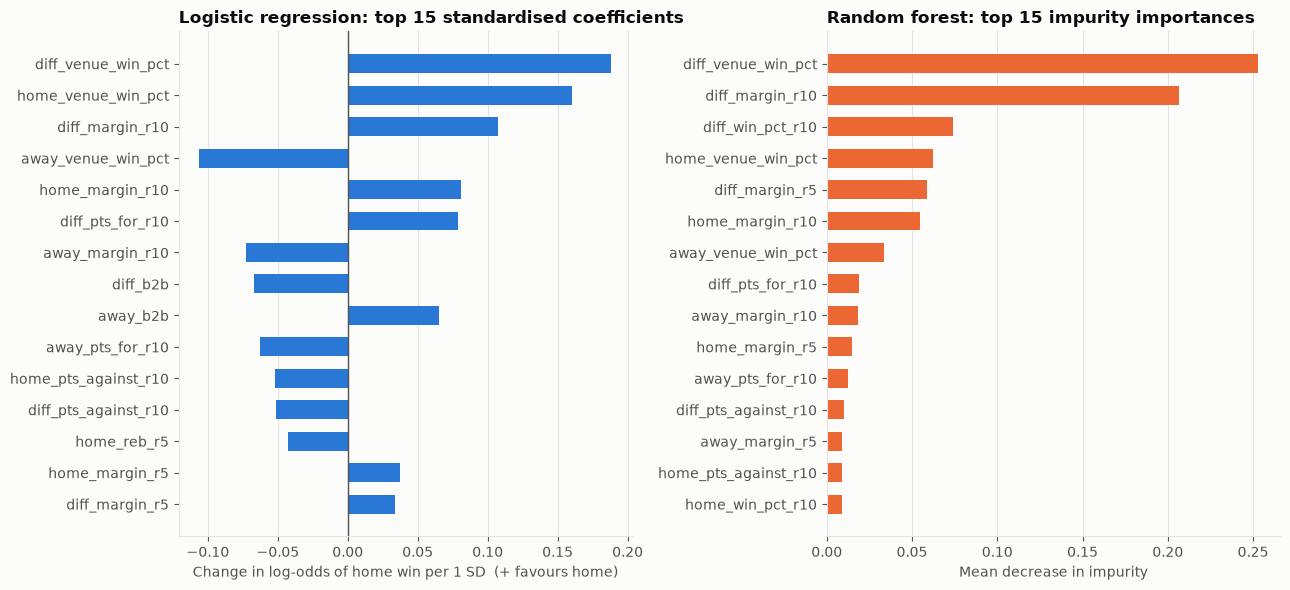

In [26]:
import os
os.makedirs("figures", exist_ok=True)

# Chart styling: two series colours (validated categorical slots 1 and 2), recessive axes and grid
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C_LR, C_RF = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

TOP_N = 15
lr_coef = pd.Series(logreg_grid.best_estimator_.named_steps["logisticregression"].coef_[0], index=FEATURES)
rf_imp = pd.Series(rf_grid.best_estimator_.feature_importances_, index=FEATURES)

lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(TOP_N)[::-1]
rf_top = rf_imp.sort_values(ascending=False).head(TOP_N)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
ax = axes[0]
ax.barh(lr_top.index, lr_top.values, color=C_LR, height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_title(f"Logistic regression: top {TOP_N} standardised coefficients", loc="left")
ax.set_xlabel("Change in log-odds of home win per 1 SD  (+ favours home)")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(rf_top.index, rf_top.values, color=C_RF, height=0.6)
ax.set_title(f"Random forest: top {TOP_N} impurity importances", loc="left")
ax.set_xlabel("Mean decrease in impurity")
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig("figures/feature_importance.png", dpi=150)
plt.show()

In [27]:
# Same information as a table, plus importance aggregated by feature group
imp_table = pd.DataFrame({"lr_coef": lr_coef, "lr_abs_coef": lr_coef.abs(), "rf_importance": rf_imp})
print("Top 10 features by |LR coefficient|:")
print(imp_table.sort_values("lr_abs_coef", ascending=False).head(10).round(4).to_string())
print("\nTop 10 features by RF importance:")
print(imp_table.sort_values("rf_importance", ascending=False).head(10).round(4).to_string())

def feature_group(f):
    base = f.split("_", 1)[1]                       # strip home_/away_/diff_
    for w in WINDOWS:
        base = base.replace(f"_r{w}", "")
    return base
groups = imp_table.groupby(imp_table.index.map(feature_group)).agg(
    lr_sum_abs_coef=("lr_abs_coef", "sum"), rf_sum_importance=("rf_importance", "sum"))
print("\nRest / back-to-back coefficients (standardised):")
print(lr_coef[[c for c in FEATURES if "b2b" in c or "rest_days" in c]].round(4).to_string())
print("\nImportance summed by feature group:")
print(groups.assign(rf_share=groups.rf_sum_importance / groups.rf_sum_importance.sum())
      .sort_values("rf_sum_importance", ascending=False).round(4).to_string())

Top 10 features by |LR coefficient|:
                    lr_coef  lr_abs_coef  rf_importance
diff_venue_win_pct   0.1884       0.1884         0.2531
home_venue_win_pct   0.1600       0.1600         0.0622
diff_margin_r10      0.1073       0.1073         0.2064
away_venue_win_pct  -0.1061       0.1061         0.0333
home_margin_r10      0.0808       0.0808         0.0546
diff_pts_for_r10     0.0787       0.0787         0.0187
away_margin_r10     -0.0729       0.0729         0.0185
diff_b2b            -0.0673       0.0673         0.0035
away_b2b             0.0651       0.0651         0.0037
away_pts_for_r10    -0.0629       0.0629         0.0124

Top 10 features by RF importance:
                    lr_coef  lr_abs_coef  rf_importance
diff_venue_win_pct   0.1884       0.1884         0.2531
diff_margin_r10      0.1073       0.1073         0.2064
diff_win_pct_r10     0.0108       0.0108         0.0740
home_venue_win_pct   0.1600       0.1600         0.0622
diff_margin_r5       0.0340     

### Calibration

A calibration curve checks whether a predicted 70% chance really comes true about 70% of the time. We
bin test games into 10 equal-count bins of predicted probability and plot the observed home-win
rate against the mean prediction in each bin. The Brier score (mean squared error of the
probabilities; lower is better) summarises it. For reference, a constant prediction equal to the
training-set home-win rate is also scored.

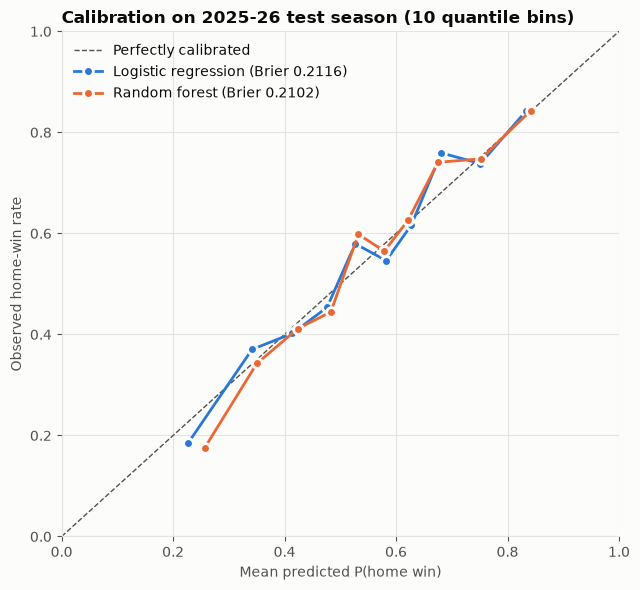

Brier score, Logistic regression: 0.2116
Brier score, Random forest: 0.2102
Brier score, Constant (train home-win rate): 0.2478


In [28]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color=INK_2, linewidth=1, label="Perfectly calibrated")
brier = {}
for name, color in [("Logistic regression", C_LR), ("Random forest", C_RF)]:
    frac_pos, mean_pred = calibration_curve(y_test, test_proba[name], n_bins=10, strategy="quantile")
    brier[name] = brier_score_loss(y_test, test_proba[name])
    ax.plot(mean_pred, frac_pos, marker="o", markersize=7, linewidth=2, color=color,
            markeredgecolor=SURFACE, markeredgewidth=2, label=f"{name} (Brier {brier[name]:.4f})")
brier["Constant (train home-win rate)"] = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted P(home win)")
ax.set_ylabel("Observed home-win rate")
ax.set_title("Calibration on 2025-26 test season (10 quantile bins)", loc="left")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig("figures/calibration.png", dpi=150)
plt.show()

for k, v in brier.items():
    print(f"Brier score, {k}: {v:.4f}")

## 6. Summary of results

Everything below is computed above in this notebook. Copy from here.

In [29]:
def fmt(k, pct=True):
    r = ci_df.loc[k]
    if pct:
        return f"{100*r.estimate:.1f}% (95% CI {100*r.ci_low:.1f}–{100*r.ci_high:.1f}%)"
    return f"{r.estimate:.3f} (95% CI {r.ci_low:.3f}–{r.ci_high:.3f})"

print("=" * 78)
print("NBA HOME-WIN PREDICTOR: FINAL RESULTS")
print("=" * 78)
print(f"Data: {len(model_df):,} regular-season + NBA Cup games, 2015-16 to 2025-26 "
      f"(first {MIN_GAMES} games per team-season excluded)")
print(f"Train: {len(train):,} games (2015-16 to 2024-25) | Test: {len(test):,} games (2025-26, held out)")
print(f"Features: {len(FEATURES)} pre-game features (rolling 5/10-game form, rest, venue win %)")
print("-" * 78)
print(f"{'Model':<26}{'Test accuracy':<34}{'Test ROC AUC'}")
print(f"{'Baseline (always home)':<26}{fmt('acc_base'):<34}0.500 (constant)")
print(f"{'Logistic regression':<26}{fmt('acc_lr'):<34}{fmt('auc_lr', pct=False)}")
print(f"{'Random forest':<26}{fmt('acc_rf'):<34}{fmt('auc_rf', pct=False)}")
print("-" * 78)
print(f"CV ROC AUC (TimeSeriesSplit, 5 folds, train seasons): "
      f"LR {logreg_grid.best_score_:.3f} | RF {rf_grid.best_score_:.3f}")
print(f"Accuracy gain over baseline: LR +{100*point['acc_lr-base']:.1f} pts "
      f"(95% CI {100*ci_df.loc['acc_lr-base','ci_low']:.1f} to {100*ci_df.loc['acc_lr-base','ci_high']:.1f}) | "
      f"RF +{100*point['acc_rf-base']:.1f} pts "
      f"(95% CI {100*ci_df.loc['acc_rf-base','ci_low']:.1f} to {100*ci_df.loc['acc_rf-base','ci_high']:.1f})")
print(f"RF − LR: accuracy {100*point['acc_rf-lr']:+.1f} pts "
      f"(95% CI {100*ci_df.loc['acc_rf-lr','ci_low']:.1f} to {100*ci_df.loc['acc_rf-lr','ci_high']:.1f}), "
      f"AUC {point['auc_rf-lr']:+.3f} "
      f"(95% CI {ci_df.loc['auc_rf-lr','ci_low']:.3f} to {ci_df.loc['auc_rf-lr','ci_high']:.3f})")
print(f"Brier score: LR {brier['Logistic regression']:.4f} | RF {brier['Random forest']:.4f} | "
      f"constant {brier['Constant (train home-win rate)']:.4f}")
print("=" * 78)

NBA HOME-WIN PREDICTOR: FINAL RESULTS
Data: 11,495 regular-season + NBA Cup games, 2015-16 to 2025-26 (first 10 games per team-season excluded)
Train: 10,419 games (2015-16 to 2024-25) | Test: 1,076 games (2025-26, held out)
Features: 45 pre-game features (rolling 5/10-game form, rest, venue win %)
------------------------------------------------------------------------------
Model                     Test accuracy                     Test ROC AUC
Baseline (always home)    54.9% (95% CI 52.0–58.0%)         0.500 (constant)
Logistic regression       66.7% (95% CI 63.9–69.5%)         0.720 (95% CI 0.689–0.750)
Random forest             67.1% (95% CI 64.3–69.9%)         0.725 (95% CI 0.695–0.756)
------------------------------------------------------------------------------
CV ROC AUC (TimeSeriesSplit, 5 folds, train seasons): LR 0.691 | RF 0.687
Accuracy gain over baseline: LR +11.8 pts (95% CI 8.2 to 15.5) | RF +12.2 pts (95% CI 8.7 to 15.8)
RF − LR: accuracy +0.4 pts (95% CI -1.0 to 1.